# Model Evaluation and Testing


In [ ]:
!pip install xgboost scikit-learn shap SkillMetrics scipy openpyxl optuna -q

## 1. Konfigurasi Lingkungan dan Reprodusibilitas

In [ ]:
import os
import sys
import time
import json
import zipfile
import warnings
import platform
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import skill_metrics as sm
import sklearn
import xgboost as xgb
import scipy
import optuna
from scipy.stats import wilcoxon, pearsonr, ks_2samp
from sklearn.model_selection import KFold, GroupKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.multioutput import MultiOutputRegressor
from sklearn.cluster import KMeans
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

OUT_DIR = 'hasil_revisi_bittech'
os.makedirs(OUT_DIR, exist_ok=True)

env_info = {
    'Python_Version': sys.version.split()[0],
    'Platform': platform.platform(),
    'CPU_Cores': os.cpu_count(),
    'NumPy_Version': np.__version__,
    'Pandas_Version': pd.__version__,
    'Scikit_Learn_Version': sklearn.__version__,
    'XGBoost_Version': xgb.__version__,
    'SciPy_Version': scipy.__version__,
    'Optuna_Version': optuna.__version__,
    'SHAP_Version': shap.__version__,
    'Random_Seed': RANDOM_SEED
}
print('Konfigurasi Lingkungan Komputasi:')
for k, v in env_info.items():
    print(f'{k:22s}: {v}')
with open(os.path.join(OUT_DIR, 'Environment_Reproducibility_Config.json'), 'w') as f:
    json.dump(env_info, f, indent=2)

Konfigurasi Lingkungan Komputasi:
Python_Version        : 3.13.16
Platform              : Linux-6.6.122+-x86_64-with-glibc2.39
CPU_Cores             : 2
NumPy_Version         : 2.1.3
Pandas_Version        : 2.2.3
Scikit_Learn_Version  : 1.6.1
XGBoost_Version       : 3.4.1
SciPy_Version         : 1.16.3
Optuna_Version        : 5.0.0
SHAP_Version          : 0.54.1
Random_Seed           : 42


## 2. Akuisisi Data, Verifikasi Provenance, dan Distribusi Statistik

In [ ]:
from google.colab import files

data_path = 'dataset_200k_with_coords.csv'
if not os.path.exists(data_path):
    uploaded = files.upload()
    data_path = list(uploaded.keys())[0]

print(f'Memuat dataset dari: {data_path}')
df = pd.read_csv(data_path)

fitur_terbaik = [
    'Vp_7000m', 'crustal_thickness', 'dVs_20km', 'Vp_6000m',
    'VpVs_60km', 'dVs_60km', 'gg_mantle_60km', 'dVpVs_60km',
    'dVs_40km', 'elevation_detrend'
]
target_cols = ['T_1000m', 'T_2000m', 'T_3000m', 'T_4000m', 'T_5000m']

if 'Lat' not in df.columns or 'Long' not in df.columns:
    for col in df.select_dtypes(include=['object']).columns:
        if df[col].astype(str).str.contains('POINT').any():
            df['Long'] = df[col].str.extract(r'POINT \(([-0-9.]+)')[0].astype(float)
            df['Lat'] = df[col].str.extract(r'POINT \([-0-9.]+ ([-0-9.]+)\)')[0].astype(float)

if len(df) > 200000:
    print(f'Random sampling 200.000 baris dari {len(df):,} baris:')
    df = df.sample(n=200000, random_state=RANDOM_SEED).reset_index(drop=True)

n_missing = int(df[fitur_terbaik + target_cols].isnull().sum().sum())
n_dup_coords = int(df.duplicated(subset=['Lat', 'Long']).sum()) if ('Lat' in df.columns and 'Long' in df.columns) else 0
print(f'Jumlah sampel             : {len(df):,}')
print(f'Jumlah missing values     : {n_missing}')
print(f'Duplikat koordinat        : {n_dup_coords}')
if 'Lat' in df.columns and 'Long' in df.columns:
    print(f'Rentang Latitude          : {df["Lat"].min():.4f} s/d {df["Lat"].max():.4f}')
    print(f'Rentang Longitude         : {df["Long"].min():.4f} s/d {df["Long"].max():.4f}')

dist_rows = []
for col in fitur_terbaik + target_cols:
    s = df[col]
    dist_rows.append({
        'Variable': col,
        'Role': 'Input Predictor' if col in fitur_terbaik else 'Target Depth',
        'Mean': s.mean(),
        'Std_Dev': s.std(),
        'Min': s.min(),
        'Q25': s.quantile(0.25),
        'Median': s.median(),
        'Q75': s.quantile(0.75),
        'Max': s.max(),
        'IQR': s.quantile(0.75) - s.quantile(0.25),
        'Skewness': s.skew()
    })
df_dist = pd.DataFrame(dist_rows)
df_dist.to_excel(os.path.join(OUT_DIR, 'Tabel_1_Provenance_dan_Distribusi_Dataset.xlsx'), index=False)
display(df_dist.round(4))

Memuat dataset dari: dataset_200k_with_coords.csv
Jumlah sampel             : 200,000
Jumlah missing values     : 0
Duplikat koordinat        : 0
Rentang Latitude          : 24.5436 s/d 49.3697
Rentang Longitude         : -124.7406 s/d -67.2871


,Variable,Role,Mean,Std_Dev,Min,Q25,Median,Q75,Max,IQR,Skewness
0,Vp_7000m,Input Predictor,6.0415,0.3165,3.4988,5.9088,6.1148,6.2368,6.5510,0.3280,-3.1777
1,crustal_thickness,Input Predictor,41.0709,6.5035,20.3189,35.9937,42.1040,46.5700,54.7268,10.5763,-0.3784
2,dVs_20km,Input Predictor,3.0919,1.5751,-1.6672,1.9625,3.0283,4.2364,8.1714,2.2739,0.1041
3,Vp_6000m,Input Predictor,6.0361,0.3197,3.4950,5.9034,6.1100,6.2330,6.5510,0.3296,-3.1779
4,VpVs_60km,Input Predictor,1.7550,0.0101,1.7265,1.7483,1.7536,1.7604,1.8037,0.0121,0.7163
5,dVs_60km,Input Predictor,2.4102,1.9206,-4.5613,1.0510,2.8646,3.8406,6.5176,2.7896,-0.6494
6,gg_mantle_60km,Input Predictor,13.1952,3.1937,4.5171,10.8676,12.8115,15.8090,21.9217,4.9413,0.1039
7,dVpVs_60km,Input Predictor,-1.0073,0.5092,-2.5774,-1.3686,-1.0522,-0.7400,1.4426,0.6286,0.7049
8,dVs_40km,Input Predictor,3.3743,1.5923,-3.1606,2.4130,3.5358,4.5168,8.3492,2.1038,-0.4948
9,elevation_detrend,Input Predictor,-0.1189,96.9830,-788.2494,-21.4132,-1.4173,13.4850,983.8196,34.8982,1.1263


## 3. Pemisahan Independen Optimasi Hiperparameter Optuna vs Evaluasi
Proses tuning dijalankan pada partisi data terisolasi menggunakan search space TPE Optuna (30 trials) sebelum menguji parameter terbaik pada skema 5-Fold Cross-Validation dan Spatial Block Cross-Validation.

In [ ]:
X_raw = df[fitur_terbaik].values.astype(np.float32)
Y = df[target_cols].values.astype(np.float64)

# Partisi tuning (10% = 20.000 sampel) dan partisi evaluasi independen (90% = 180.000 sampel)
tune_indices, eval_holdout_indices = train_test_split(
    np.arange(len(df)), test_size=0.90, random_state=RANDOM_SEED
)
X_tune_raw, Y_tune = X_raw[tune_indices], Y[tune_indices]

def objective(trial):
    rf_n = trial.suggest_int('rf_n_estimators', 100, 300, step=50)
    rf_d = trial.suggest_int('rf_max_depth', 10, 20)
    xgb_n = trial.suggest_int('xgb_n_estimators', 100, 300, step=50)
    xgb_d = trial.suggest_int('xgb_max_depth', 10, 20)
    xgb_lr = trial.suggest_float('xgb_learning_rate', 0.05, 0.20, log=True)

    kf_inner = KFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED)
    fold_rmses = []
    for tr_i, va_i in kf_inner.split(X_tune_raw):
        sc_inner = StandardScaler()
        X_tr_in = sc_inner.fit_transform(X_tune_raw[tr_i])
        X_va_in = sc_inner.transform(X_tune_raw[va_i])

        rf_m = RandomForestRegressor(n_estimators=rf_n, max_depth=rf_d, random_state=RANDOM_SEED, n_jobs=-1).fit(X_tr_in, Y_tune[tr_i])
        xgb_m = MultiOutputRegressor(XGBRegressor(n_estimators=xgb_n, max_depth=xgb_d, learning_rate=xgb_lr, random_state=RANDOM_SEED, n_jobs=-1)).fit(X_tr_in, Y_tune[tr_i])
        pred_ens = 0.5 * rf_m.predict(X_va_in) + 0.5 * xgb_m.predict(X_va_in)
        fold_rmses.append(np.sqrt(mean_squared_error(Y_tune[va_i], pred_ens)))
    return float(np.mean(fold_rmses))

optuna.logging.set_verbosity(optuna.logging.WARNING)

print('Menjalankan 30 trial TPE Optuna pada partisi tuning independen...')
study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=RANDOM_SEED))
study.optimize(objective, n_trials=30)
best_p = study.best_params

print('Hasil optimasi TPE Optuna:')
for k, v in best_p.items():
    print(f'{k}: {v}')

df_trials = study.trials_dataframe()
df_trials.to_csv(os.path.join(OUT_DIR, 'Optuna_30_Trials_History.csv'), index=False)

optuna_config_doc = {
    'Sampler': 'TPESampler(seed=42)',
    'Trials': 30,
    'Tuning_Partition_Samples': int(len(X_tune_raw)),
    'Disjoint_Evaluation_Samples': int(len(eval_holdout_indices)),
    'Search_Space': {
        'rf_n_estimators': [100, 300],
        'rf_max_depth': [10, 20],
        'xgb_n_estimators': [100, 300],
        'xgb_max_depth': [10, 20],
        'xgb_learning_rate': [0.05, 0.20]
    },
    'Selected_Best_Parameters': best_p
}
with open(os.path.join(OUT_DIR, 'Optuna_Hyperparameter_Configuration.json'), 'w') as f:
    json.dump(optuna_config_doc, f, indent=2)

Menjalankan 30 trial TPE Optuna pada partisi tuning independen...
Hasil optimasi TPE Optuna:
rf_n_estimators: 100
rf_max_depth: 20
xgb_n_estimators: 300
xgb_max_depth: 10
xgb_learning_rate: 0.17332572893079348


## 4. Evaluasi 5-Fold Cross-Validation dan Studi Ablasi
Evaluasi model pembanding dengan standardisasi di dalam fold pelatihan dan pelatihan meta-learner berbasis prediksi Out-of-Fold (OOF) internal.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
fold_splits = list(kf.split(X_raw))

oof_preds = {
    'Linear_Regression': np.zeros_like(Y),
    'RF_Default': np.zeros_like(Y),
    'XGB_Default': np.zeros_like(Y),
    'RF_Optuna_MultiOutput': np.zeros_like(Y),
    'XGB_Optuna_MultiOutput': np.zeros_like(Y),
    'XGB_Optuna_SingleOutput': np.zeros_like(Y),
    'Simple_Average_Ensemble': np.zeros_like(Y),
    'Hybrid_Stacking_Proposed': np.zeros_like(Y),
    'Hybrid_Stacking_CrossDepth': np.zeros_like(Y),
}

meta_weights_records = []
t0 = time.time()

for fold_idx, (tr_idx, te_idx) in enumerate(fold_splits):
    f_start = time.time()
    print(f'Melatih dan mengevaluasi Fold {fold_idx+1}/5...')
    scaler_fold = StandardScaler()
    X_tr = scaler_fold.fit_transform(X_raw[tr_idx])
    X_te = scaler_fold.transform(X_raw[te_idx])
    Y_tr, Y_te = Y[tr_idx], Y[te_idx]

    # 1. Multiple Linear Regression Baseline
    mdl_lr = LinearRegression().fit(X_tr, Y_tr)
    oof_preds['Linear_Regression'][te_idx] = mdl_lr.predict(X_te)

    # 2. RF Default Baseline (n_estimators=100, max_depth=10)
    mdl_rf_def = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=RANDOM_SEED, n_jobs=-1).fit(X_tr, Y_tr)
    oof_preds['RF_Default'][te_idx] = mdl_rf_def.predict(X_te)

    # 3. XGBoost Default Baseline (n_estimators=100, max_depth=6, learning_rate=0.3)
    mdl_xgb_def = XGBRegressor(n_estimators=100, max_depth=6, learning_rate=0.3, random_state=RANDOM_SEED, n_jobs=-1).fit(X_tr, Y_tr)
    oof_preds['XGB_Default'][te_idx] = mdl_xgb_def.predict(X_te)

    # 4. XGBoost Optuna (Native Multi-Output Tree)
    mdl_xgb_multi = XGBRegressor(
        n_estimators=best_p['xgb_n_estimators'],
        max_depth=best_p['xgb_max_depth'],
        learning_rate=best_p['xgb_learning_rate'],
        random_state=RANDOM_SEED,
        n_jobs=-1
    ).fit(X_tr, Y_tr)
    oof_preds['XGB_Optuna_MultiOutput'][te_idx] = mdl_xgb_multi.predict(X_te)

    # 5. Internal 3-Fold OOF di dalam X_tr untuk melatih Meta-Learner tanpa data leaked
    kf_meta = KFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED)
    rf_inner_oof = np.zeros_like(Y_tr)
    xgb_inner_oof = np.zeros_like(Y_tr)

    for m_tr, m_va in kf_meta.split(X_tr):
        rf_in = RandomForestRegressor(
            n_estimators=best_p['rf_n_estimators'], max_depth=best_p['rf_max_depth'], max_samples=0.7, random_state=RANDOM_SEED, n_jobs=-1
        ).fit(X_tr[m_tr], Y_tr[m_tr])
        rf_inner_oof[m_va] = rf_in.predict(X_tr[m_va])

        xgb_in = MultiOutputRegressor(
            XGBRegressor(
                n_estimators=best_p['xgb_n_estimators'],
                max_depth=best_p['xgb_max_depth'],
                learning_rate=best_p['xgb_learning_rate'],
                random_state=RANDOM_SEED,
                n_jobs=-1
            )
        ).fit(X_tr[m_tr], Y_tr[m_tr])
        xgb_inner_oof[m_va] = xgb_in.predict(X_tr[m_va])

    # 6. Refit Base Learners pada seluruh X_tr untuk inferensi pada X_te
    mdl_rf_opt = RandomForestRegressor(
        n_estimators=best_p['rf_n_estimators'], max_depth=best_p['rf_max_depth'], random_state=RANDOM_SEED, n_jobs=-1
    ).fit(X_tr, Y_tr)
    p_rf_te = mdl_rf_opt.predict(X_te)
    oof_preds['RF_Optuna_MultiOutput'][te_idx] = p_rf_te

    mdl_xgb_single = MultiOutputRegressor(
        XGBRegressor(
            n_estimators=best_p['xgb_n_estimators'],
            max_depth=best_p['xgb_max_depth'],
            learning_rate=best_p['xgb_learning_rate'],
            random_state=RANDOM_SEED,
            n_jobs=-1
        )
    ).fit(X_tr, Y_tr)
    p_xgb_te = mdl_xgb_single.predict(X_te)
    oof_preds['XGB_Optuna_SingleOutput'][te_idx] = p_xgb_te

    # 7. Simple Averaging Ensemble
    oof_preds['Simple_Average_Ensemble'][te_idx] = 0.5 * p_rf_te + 0.5 * p_xgb_te

    # 8. Depth-Specific Stacking Meta-Learner (dilatih pada rf_inner_oof dan xgb_inner_oof)
    for d, col in enumerate(target_cols):
        Z_tr = np.column_stack([rf_inner_oof[:, d], xgb_inner_oof[:, d]])
        Z_te = np.column_stack([p_rf_te[:, d], p_xgb_te[:, d]])
        meta_lr = LinearRegression().fit(Z_tr, Y_tr[:, d])
        oof_preds['Hybrid_Stacking_Proposed'][te_idx, d] = meta_lr.predict(Z_te)
        meta_weights_records.append({
            'Fold': fold_idx + 1,
            'Target_Depth': col,
            'Intercept_Beta0': meta_lr.intercept_,
            'Weight_RF_Beta1': meta_lr.coef_[0],
            'Weight_XGB_Beta2': meta_lr.coef_[1]
        })

    # 9. Cross-Depth Multi-Output Stacking Meta-Learner (N x 10 matriks meta-fitur lintas kedalaman)
    Z10_tr = np.hstack([rf_inner_oof, xgb_inner_oof])
    Z10_te = np.hstack([p_rf_te, p_xgb_te])
    meta_multi = Ridge(alpha=1.0).fit(Z10_tr, Y_tr)
    oof_preds['Hybrid_Stacking_CrossDepth'][te_idx] = meta_multi.predict(Z10_te)

    print(f'Selesai Fold {fold_idx+1}/5 dalam {(time.time() - f_start)/60:.2f} menit')

df_meta_weights = pd.DataFrame(meta_weights_records)
df_meta_summary = df_meta_weights.groupby('Target_Depth', sort=False)[['Intercept_Beta0', 'Weight_RF_Beta1', 'Weight_XGB_Beta2']].mean().reset_index()
df_meta_summary.to_excel(os.path.join(OUT_DIR, 'Tabel_3_Bobot_Meta_Learner_Per_Kedalaman.xlsx'), index=False)
print('Bobot Rata-rata Meta-Learner (Linear Regression) per Kedalaman:')
display(df_meta_summary.round(4))

Melatih dan mengevaluasi Fold 1/5...
Selesai Fold 1/5 dalam 20.48 menit
Melatih dan mengevaluasi Fold 2/5...
Selesai Fold 2/5 dalam 20.30 menit
Melatih dan mengevaluasi Fold 3/5...
Selesai Fold 3/5 dalam 20.46 menit
Melatih dan mengevaluasi Fold 4/5...
Selesai Fold 4/5 dalam 20.37 menit
Melatih dan mengevaluasi Fold 5/5...
Selesai Fold 5/5 dalam 20.40 menit
Bobot Rata-rata Meta-Learner (Linear Regression) per Kedalaman:


,Target_Depth,Intercept_Beta0,Weight_RF_Beta1,Weight_XGB_Beta2
0,T_1000m,-1.2163,0.3626,0.6675
1,T_2000m,-1.1566,0.3994,0.6187
2,T_3000m,-1.1769,0.4335,0.5801
3,T_4000m,-1.1483,0.4458,0.5648
4,T_5000m,-1.1642,0.4244,0.5846


## 5. Tabel Ablation Study dan Analisis Error Spesifik Kedalaman
Menghitung metrik pada 200.000 sampel dan memverifikasi konsistensi pada 180.000 sampel diluar partisi tuning Optuna.

In [ ]:
ablation_rows = []
for m_name, preds in oof_preds.items():
    for d, col in enumerate(target_cols):
        y_t = Y[:, d]
        y_p = preds[:, d]
        res = y_p - y_t
        sigma_y = np.std(y_t)

        fold_rmses = [np.sqrt(mean_squared_error(Y[te, d], preds[te, d])) for _, te in fold_splits]
        fold_maes = [mean_absolute_error(Y[te, d], preds[te, d]) for _, te in fold_splits]
        fold_r2s = [r2_score(Y[te, d], preds[te, d]) for _, te in fold_splits]

        # Verifikasi RMSE pada 180.000 sampel diluar partisi tuning Optuna
        rmse_disjoint_180k = np.sqrt(mean_squared_error(Y[eval_holdout_indices, d], preds[eval_holdout_indices, d]))

        pi_low, pi_high = np.percentile(res, [2.5, 97.5])
        ablation_rows.append({
            'Model': m_name,
            'Target_Depth': col,
            'Target_SD_C': sigma_y,
            'RMSE_C': np.mean(fold_rmses),
            'RMSE_Fold_SD': np.std(fold_rmses, ddof=1),
            'RMSE_Disjoint_180k_C': rmse_disjoint_180k,
            'MAE_C': np.mean(fold_maes),
            'R2_Pct': np.mean(fold_r2s) * 100.0,
            'NRMSE_Pct_of_SD': (np.mean(fold_rmses) / sigma_y) * 100.0,
            'Bias_Mean_Residual_C': np.mean(res),
            'Residual_SD_C': np.std(res),
            'PI95_Lower_C': pi_low,
            'PI95_Upper_C': pi_high,
            'Pearson_r': pearsonr(y_t, y_p)[0]
        })

df_ablation_full = pd.DataFrame(ablation_rows)
df_ablation_summary = df_ablation_full.groupby('Model', sort=False)[
    ['RMSE_C', 'RMSE_Fold_SD', 'RMSE_Disjoint_180k_C', 'MAE_C', 'R2_Pct', 'NRMSE_Pct_of_SD', 'Bias_Mean_Residual_C']
].mean().reset_index()

with pd.ExcelWriter(os.path.join(OUT_DIR, 'Tabel_2_Ablation_Study_dan_Error_Per_Kedalaman.xlsx')) as writer:
    df_ablation_summary.to_excel(writer, sheet_name='Ringkasan_Ablation_Rata2', index=False)
    df_ablation_full.to_excel(writer, sheet_name='Detail_Per_Kedalaman', index=False)

print('Ringkasan Ablation Study (Rata-rata 5 Kedalaman):')
display(df_ablation_summary.round(4))
print('Detail Performa Hybrid Stacking per Kedalaman:')
display(df_ablation_full[df_ablation_full['Model'] == 'Hybrid_Stacking_Proposed'].round(4))

Ringkasan Ablation Study (Rata-rata 5 Kedalaman):


,Model,RMSE_C,RMSE_Fold_SD,RMSE_Disjoint_180k_C,MAE_C,R2_Pct,NRMSE_Pct_of_SD,Bias_Mean_Residual_C
0,Linear_Regression,8.7080,0.0670,8.7116,6.0933,68.1640,55.4380,0.0002
1,RF_Default,5.7954,0.0688,5.7991,3.9584,85.5803,37.1279,-0.0089
2,XGB_Default,4.8898,0.0707,4.8901,3.3032,89.8579,31.2172,-0.0030
3,RF_Optuna_MultiOutput,3.7207,0.0722,3.7247,2.2734,93.9714,23.9406,0.0056
4,XGB_Optuna_MultiOutput,3.6907,0.0717,3.6934,2.3158,94.1601,23.6356,-0.0032
5,XGB_Optuna_SingleOutput,3.6907,0.0717,3.6934,2.3158,94.1601,23.6356,-0.0032
6,Simple_Average_Ensemble,3.5696,0.0716,3.5731,2.2093,94.5049,22.9012,0.0012
7,Hybrid_Stacking_Proposed,3.5648,0.0705,3.5681,2.2215,94.5298,22.8573,-0.0002
8,Hybrid_Stacking_CrossDepth,3.5160,0.0697,3.5191,2.1917,94.6760,22.5455,0.0007


Detail Performa Hybrid Stacking per Kedalaman:


,Model,Target_Depth,Target_SD_C,RMSE_C,RMSE_Fold_SD,RMSE_Disjoint_180k_C,MAE_C,R2_Pct,NRMSE_Pct_of_SD,Bias_Mean_Residual_C,Residual_SD_C,PI95_Lower_C,PI95_Upper_C,Pearson_r
35,Hybrid_Stacking_Proposed,T_1000m,9.0236,2.8344,0.1286,2.8344,1.4956,90.1249,31.4116,0.0004,2.8368,-4.5787,4.8131,0.9493
36,Hybrid_Stacking_Proposed,T_2000m,12.8565,3.1707,0.0645,3.1747,1.9477,93.9171,24.6622,-0.0052,3.1712,-6.0971,6.3087,0.9691
37,Hybrid_Stacking_Proposed,T_3000m,16.4763,3.5770,0.0586,3.5816,2.2854,95.2864,21.7101,-0.0018,3.5774,-7.1465,7.3620,0.9761
38,Hybrid_Stacking_Proposed,T_4000m,20.3799,3.9055,0.0589,3.9106,2.5323,96.3274,19.1633,0.0022,3.9058,-7.9321,8.0684,0.9815
39,Hybrid_Stacking_Proposed,T_5000m,25.0081,4.3363,0.0422,4.3390,2.8464,96.9934,17.3395,0.0036,4.3364,-8.9190,8.9241,0.9849


## 6. Uji Signifikansi Statistik Wilcoxon Berpasangan dan Effect Size
Uji Wilcoxon berpasangan pada tingkat residual sampel dan tingkat 50 blok.

In [ ]:
if 'Lat' in df.columns and 'Long' in df.columns:
    coords = df[['Lat', 'Long']].values
    kmeans_50 = KMeans(n_clusters=50, random_state=RANDOM_SEED, n_init=10).fit(coords)
    spatial_blocks_50 = kmeans_50.labels_
else:
    spatial_blocks_50 = np.arange(len(df)) % 50

comparisons = [
    ('Hybrid_Stacking_Proposed', 'RF_Optuna_MultiOutput'),
    ('Hybrid_Stacking_Proposed', 'XGB_Optuna_SingleOutput'),
    ('Hybrid_Stacking_Proposed', 'Simple_Average_Ensemble'),
    ('Hybrid_Stacking_Proposed', 'RF_Default'),
    ('Hybrid_Stacking_Proposed', 'XGB_Default'),
    ('Hybrid_Stacking_CrossDepth', 'Hybrid_Stacking_Proposed')
]

wilcoxon_rows = []
for m_prop, m_base in comparisons:
    for d, col in enumerate(target_cols):
        err_prop = np.abs(Y[:, d] - oof_preds[m_prop][:, d])
        err_base = np.abs(Y[:, d] - oof_preds[m_base][:, d])
        diff = err_base - err_prop

        res_sample = wilcoxon(err_prop, err_base, alternative='two-sided', method='approx')
        n_nz = int(np.sum(diff != 0))
        r_rb = 1.0 - (2.0 * res_sample.statistic) / (n_nz * (n_nz + 1) / 2.0)
        cohens_dz = np.mean(diff) / np.std(diff, ddof=1)
        se_diff = np.std(diff, ddof=1) / np.sqrt(len(diff))

        b_prop = [np.sqrt(mean_squared_error(Y[spatial_blocks_50 == b, d], oof_preds[m_prop][spatial_blocks_50 == b, d])) for b in range(50)]
        b_base = [np.sqrt(mean_squared_error(Y[spatial_blocks_50 == b, d], oof_preds[m_base][spatial_blocks_50 == b, d])) for b in range(50)]
        res_block = wilcoxon(b_prop, b_base, alternative='two-sided')

        wilcoxon_rows.append({
            'Comparison': f'{m_prop} vs {m_base}',
            'Target_Depth': col,
            'Sample_N': n_nz,
            'Mean_Error_Reduction_C': np.mean(diff),
            'CI95_Lower_C': np.mean(diff) - 1.96 * se_diff,
            'CI95_Upper_C': np.mean(diff) + 1.96 * se_diff,
            'Wilcoxon_W_Sample': res_sample.statistic,
            'Z_Statistic': res_sample.zstatistic,
            'p_value_Raw': res_sample.pvalue,
            'Rank_Biserial_r': r_rb,
            'Cohens_dz': cohens_dz,
            'Block50_Wilcoxon_W': res_block.statistic,
            'Block50_pvalue': res_block.pvalue
        })

df_wilcoxon = pd.DataFrame(wilcoxon_rows)
m_tot = len(df_wilcoxon)
order_s = np.argsort(df_wilcoxon['p_value_Raw'].values)
holm_s = np.zeros(m_tot)
for rank, idx in enumerate(order_s):
    holm_s[idx] = min(1.0, df_wilcoxon['p_value_Raw'].values[idx] * (m_tot - rank))
df_wilcoxon['p_value_Holm_Corrected'] = holm_s

order_b = np.argsort(df_wilcoxon['Block50_pvalue'].values)
holm_b = np.zeros(m_tot)
for rank, idx in enumerate(order_b):
    holm_b[idx] = min(1.0, df_wilcoxon['Block50_pvalue'].values[idx] * (m_tot - rank))
df_wilcoxon['Block50_pvalue_Holm'] = holm_b

df_wilcoxon.to_excel(os.path.join(OUT_DIR, 'Tabel_4_Uji_Statistik_Wilcoxon_dan_Effect_Size.xlsx'), index=False)
display(df_wilcoxon.head(15))

,Comparison,Target_Depth,Sample_N,Mean_Error_Reduction_C,CI95_Lower_C,CI95_Upper_C,Wilcoxon_W_Sample,Z_Statistic,p_value_Raw,Rank_Biserial_r,Cohens_dz,Block50_Wilcoxon_W,Block50_pvalue,p_value_Holm_Corrected,Block50_pvalue_Holm
0,Hybrid_Stacking_Proposed vs RF_Optuna_MultiOutput,T_1000m,200000,0.068836,0.064252,0.073421,9.334255e+09,-25.786024,1.272251e-146,0.066579,0.065805,121.0,4.945666e-08,1.399476e-145,6.923933e-07
1,Hybrid_Stacking_Proposed vs RF_Optuna_MultiOutput,T_2000m,200000,0.053246,0.048705,0.057787,9.669163e+09,-12.815143,1.348895e-37,0.033089,0.051390,152.0,4.565624e-07,6.744476e-37,5.478749e-06
2,Hybrid_Stacking_Proposed vs RF_Optuna_MultiOutput,T_3000m,200000,0.038417,0.033708,0.043126,9.875078e+09,-4.840108,1.297687e-06,0.012497,0.035756,220.0,2.428150e-05,3.893060e-06,2.670965e-04
3,Hybrid_Stacking_Proposed vs RF_Optuna_MultiOutput,T_4000m,200000,0.036052,0.031125,0.040980,9.911622e+09,-3.424787,6.152816e-04,0.008843,0.032067,299.0,8.156049e-04,6.152816e-04,6.524839e-03
4,Hybrid_Stacking_Proposed vs RF_Optuna_MultiOutput,T_5000m,200000,0.063066,0.057281,0.068851,9.665964e+09,-12.939058,2.709326e-38,0.033408,0.047779,222.0,2.688588e-05,1.625595e-37,2.688588e-04
5,Hybrid_Stacking_Proposed vs XGB_Optuna_SingleO...,T_1000m,200000,0.049991,0.047509,0.052474,8.776835e+09,-47.374747,0.000000e+00,0.122321,0.088246,65.0,3.134559e-10,0.000000e+00,5.015295e-09
6,Hybrid_Stacking_Proposed vs XGB_Optuna_SingleO...,T_2000m,200000,0.074645,0.071676,0.077615,8.451130e+09,-59.989188,0.000000e+00,0.154891,0.110168,39.0,1.347189e-11,0.000000e+00,2.290221e-10
7,Hybrid_Stacking_Proposed vs XGB_Optuna_SingleO...,T_3000m,200000,0.099667,0.096129,0.103206,8.257834e+09,-67.475490,0.000000e+00,0.174221,0.123451,18.0,4.494183e-13,0.000000e+00,8.089529e-12
8,Hybrid_Stacking_Proposed vs XGB_Optuna_SingleO...,T_4000m,200000,0.120318,0.116428,0.124207,8.092408e+09,-73.882388,0.000000e+00,0.190763,0.135559,5.0,1.776357e-14,0.000000e+00,3.552714e-13
9,Hybrid_Stacking_Proposed vs XGB_Optuna_SingleO...,T_5000m,200000,0.127052,0.122833,0.131271,8.124128e+09,-72.653879,0.000000e+00,0.187591,0.131968,12.0,1.243450e-13,0.000000e+00,2.362555e-12


## 7. Evaluasi Konsistensi Fisik Profil Suhu Vertikal
Perhitungan gradien suhu vertikal (dT/dz dalam C/km) dan perbandingan frekuensi inversi suhu dengan dataset referensi.

In [ ]:
intervals = [('1000m-2000m', 0, 1), ('2000m-3000m', 1, 2), ('3000m-4000m', 2, 3), ('4000m-5000m', 3, 4)]
grad_rows = []

for int_label, i1, i2 in intervals:
    g_ref = Y[:, i2] - Y[:, i1]
    grad_rows.append({
        'Model': 'Reference_Dataset (Stanford Model)',
        'Depth_Interval': int_label,
        'Mean_Gradient_C_per_km': np.mean(g_ref),
        'Std_Gradient_C_per_km': np.std(g_ref),
        'Min_Gradient_C_per_km': np.min(g_ref),
        'Max_Gradient_C_per_km': np.max(g_ref),
        'Gradient_RMSE_C_per_km': 0.0,
        'Gradient_R2_Pct': 100.0,
        'Inversion_Count_dT_lt_0': int(np.sum(g_ref < 0)),
        'Inversion_Frequency_Pct': np.mean(g_ref < 0) * 100.0
    })
    for m_name in ['RF_Optuna_MultiOutput', 'XGB_Optuna_SingleOutput', 'Hybrid_Stacking_Proposed', 'Hybrid_Stacking_CrossDepth']:
        g_pred = oof_preds[m_name][:, i2] - oof_preds[m_name][:, i1]
        grad_rows.append({
            'Model': m_name,
            'Depth_Interval': int_label,
            'Mean_Gradient_C_per_km': np.mean(g_pred),
            'Std_Gradient_C_per_km': np.std(g_pred),
            'Min_Gradient_C_per_km': np.min(g_pred),
            'Max_Gradient_C_per_km': np.max(g_pred),
            'Gradient_RMSE_C_per_km': np.sqrt(mean_squared_error(g_ref, g_pred)),
            'Gradient_R2_Pct': r2_score(g_ref, g_pred) * 100.0,
            'Inversion_Count_dT_lt_0': int(np.sum(g_pred < 0)),
            'Inversion_Frequency_Pct': np.mean(g_pred < 0) * 100.0
        })

df_grad = pd.DataFrame(grad_rows)
df_grad.to_excel(os.path.join(OUT_DIR, 'Tabel_5_Konsistensi_Fisik_Gradien_Suhu_Vertikal.xlsx'), index=False)
display(df_grad.round(4))

,Model,Depth_Interval,Mean_Gradient_C_per_km,Std_Gradient_C_per_km,Min_Gradient_C_per_km,Max_Gradient_C_per_km,Gradient_RMSE_C_per_km,Gradient_R2_Pct,Inversion_Count_dT_lt_0,Inversion_Frequency_Pct
0,Reference_Dataset (Stanford Model),1000m-2000m,23.7099,5.1903,-28.3302,92.6895,0.0000,100.0000,31,0.0155
1,RF_Optuna_MultiOutput,1000m-2000m,23.7064,4.8564,2.2236,53.7870,1.5448,91.1413,0,0.0000
2,XGB_Optuna_SingleOutput,1000m-2000m,23.7002,5.1298,-30.5755,69.2718,2.0212,84.8350,10,0.0050
3,Hybrid_Stacking_Proposed,1000m-2000m,23.7043,4.9966,-15.6042,60.8279,1.7074,89.1785,9,0.0045
4,Hybrid_Stacking_CrossDepth,1000m-2000m,23.7100,4.9803,-4.4181,55.1868,1.5014,91.6325,2,0.0010
5,Reference_Dataset (Stanford Model),2000m-3000m,22.6743,4.8276,-33.7259,72.8138,0.0000,100.0000,5,0.0025
6,RF_Optuna_MultiOutput,2000m-3000m,22.6711,4.5941,-1.3912,47.6451,1.2616,93.1710,1,0.0005
7,XGB_Optuna_SingleOutput,2000m-3000m,22.6750,4.8988,-9.6660,57.9231,1.9575,83.5587,4,0.0020
8,Hybrid_Stacking_Proposed,2000m-3000m,22.6777,4.7347,-7.3806,51.7258,1.5130,90.1776,2,0.0010
9,Hybrid_Stacking_CrossDepth,2000m-3000m,22.6768,4.6787,-4.1494,52.6266,1.2243,93.5690,1,0.0005


## 8. Evaluasi Spatially Blocked Cross-Validation
Evaluasi model pada partisi lipatan blok spasial 1.0 derajat (~100 km) menggunakan GroupKFold.

In [ ]:
if 'Lat' in df.columns and 'Long' in df.columns:
    lat_bins = np.floor(df['Lat'].values / 1.0).astype(int)
    lon_bins = np.floor(df['Long'].values / 1.0).astype(int)
    spatial_grid_groups = lat_bins * 10000 + lon_bins
else:
    spatial_grid_groups = spatial_blocks_50

gkf = GroupKFold(n_splits=5)
spatial_splits = list(gkf.split(X_raw, Y, groups=spatial_grid_groups))

oof_spatial = {
    'RF_Optuna_MultiOutput': np.zeros_like(Y),
    'XGB_Optuna_SingleOutput': np.zeros_like(Y),
    'Simple_Average_Ensemble': np.zeros_like(Y),
    'Hybrid_Stacking_Proposed': np.zeros_like(Y)
}

for fold_idx, (tr_idx, te_idx) in enumerate(spatial_splits):
    print(f'Melatih Spatial Block CV Fold {fold_idx+1}/5...')
    sc_sp = StandardScaler()
    X_tr = sc_sp.fit_transform(X_raw[tr_idx])
    X_te = sc_sp.transform(X_raw[te_idx])
    Y_tr, Y_te = Y[tr_idx], Y[te_idx]

    rf_sp = RandomForestRegressor(n_estimators=best_p['rf_n_estimators'], max_depth=best_p['rf_max_depth'], random_state=RANDOM_SEED, n_jobs=-1).fit(X_tr, Y_tr)
    p_rf_sp = rf_sp.predict(X_te)
    oof_spatial['RF_Optuna_MultiOutput'][te_idx] = p_rf_sp

    xgb_sp = MultiOutputRegressor(
        XGBRegressor(n_estimators=best_p['xgb_n_estimators'], max_depth=best_p['xgb_max_depth'], learning_rate=best_p['xgb_learning_rate'], random_state=RANDOM_SEED, n_jobs=-1)
    ).fit(X_tr, Y_tr)
    p_xgb_sp = xgb_sp.predict(X_te)
    oof_spatial['XGB_Optuna_SingleOutput'][te_idx] = p_xgb_sp
    oof_spatial['Simple_Average_Ensemble'][te_idx] = 0.5 * p_rf_sp + 0.5 * p_xgb_sp

for fold_idx, (tr_idx, te_idx) in enumerate(spatial_splits):
    for d in range(5):
        Z_tr = np.column_stack([oof_spatial['RF_Optuna_MultiOutput'][tr_idx, d], oof_spatial['XGB_Optuna_SingleOutput'][tr_idx, d]])
        Z_te = np.column_stack([oof_spatial['RF_Optuna_MultiOutput'][te_idx, d], oof_spatial['XGB_Optuna_SingleOutput'][te_idx, d]])
        meta_sp = LinearRegression().fit(Z_tr, Y[tr_idx, d])
        oof_spatial['Hybrid_Stacking_Proposed'][te_idx, d] = meta_sp.predict(Z_te)

spatial_rows = []
for m_name, preds in oof_spatial.items():
    for d, col in enumerate(target_cols):
        f_rmses = [np.sqrt(mean_squared_error(Y[te, d], preds[te, d])) for _, te in spatial_splits]
        f_maes = [mean_absolute_error(Y[te, d], preds[te, d]) for _, te in spatial_splits]
        f_r2s = [r2_score(Y[te, d], preds[te, d]) for _, te in spatial_splits]
        spatial_rows.append({
            'Validation_Scheme': '5-Fold Spatial Block CV (1.0-deg Grid)',
            'Model': m_name,
            'Target_Depth': col,
            'Spatial_RMSE_C': np.mean(f_rmses),
            'Spatial_RMSE_SD': np.std(f_rmses, ddof=1),
            'Spatial_MAE_C': np.mean(f_maes),
            'Spatial_R2_Pct': np.mean(f_r2s) * 100.0
        })

df_spatial_cv = pd.DataFrame(spatial_rows)
df_spatial_cv.to_excel(os.path.join(OUT_DIR, 'Tabel_6_Spatial_Block_Cross_Validation.xlsx'), index=False)
print('Rata-rata Performa pada Spatially Blocked Cross-Validation:')
display(df_spatial_cv.groupby('Model', sort=False)[['Spatial_RMSE_C', 'Spatial_MAE_C', 'Spatial_R2_Pct']].mean().round(4))
display(df_spatial_cv[df_spatial_cv['Model'] == 'Hybrid_Stacking_Proposed'].round(4))

Melatih Spatial Block CV Fold 1/5...
Melatih Spatial Block CV Fold 2/5...
Melatih Spatial Block CV Fold 3/5...
Melatih Spatial Block CV Fold 4/5...
Melatih Spatial Block CV Fold 5/5...
Rata-rata Performa pada Spatially Blocked Cross-Validation:


,Spatial_RMSE_C,Spatial_MAE_C,Spatial_R2_Pct
Model,,,
RF_Optuna_MultiOutput,6.1522,3.9604,83.3994
XGB_Optuna_SingleOutput,6.1172,3.9672,83.5765
Simple_Average_Ensemble,5.9509,3.8453,84.5000
Hybrid_Stacking_Proposed,5.9697,3.8554,84.4089


,Validation_Scheme,Model,Target_Depth,Spatial_RMSE_C,Spatial_RMSE_SD,Spatial_MAE_C,Spatial_R2_Pct
15,5-Fold Spatial Block CV (1.0-deg Grid),Hybrid_Stacking_Proposed,T_1000m,4.6680,0.3654,2.6727,72.6672
16,5-Fold Spatial Block CV (1.0-deg Grid),Hybrid_Stacking_Proposed,T_2000m,5.3642,0.1324,3.4166,82.1282
17,5-Fold Spatial Block CV (1.0-deg Grid),Hybrid_Stacking_Proposed,T_3000m,6.0356,0.1957,3.9519,86.2588
18,5-Fold Spatial Block CV (1.0-deg Grid),Hybrid_Stacking_Proposed,T_4000m,6.5311,0.2918,4.3509,89.5328
19,5-Fold Spatial Block CV (1.0-deg Grid),Hybrid_Stacking_Proposed,T_5000m,7.2494,0.4089,4.8850,91.4574


## 9. Visualisasi Evaluasi Model, Diagram Taylor Multi-Kedalaman, dan Analisis SHAP Ensemble

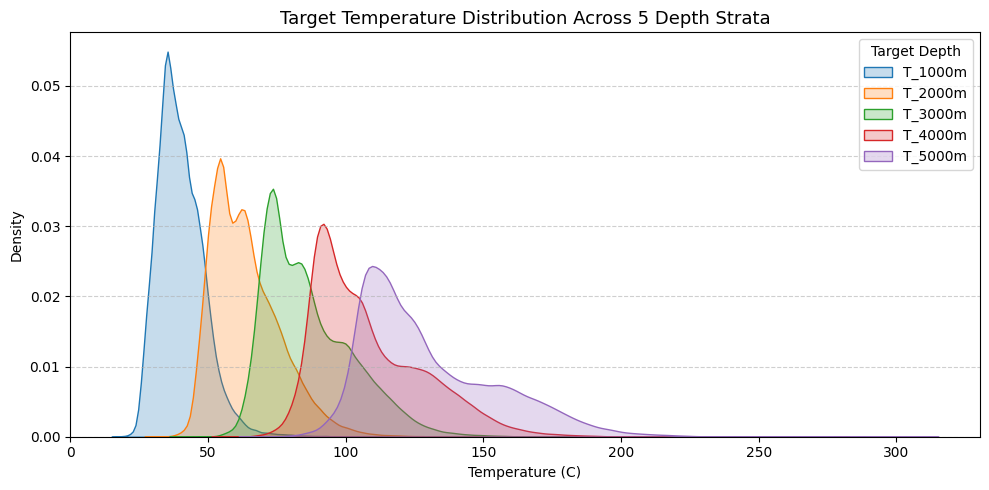

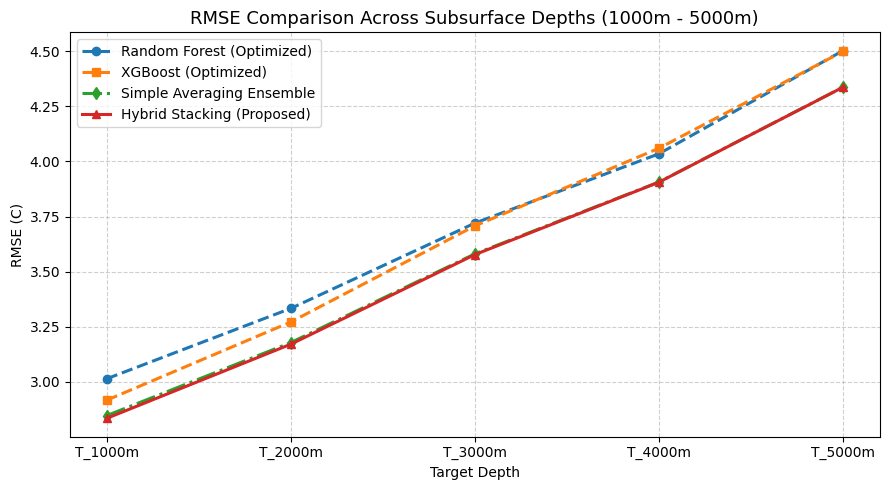

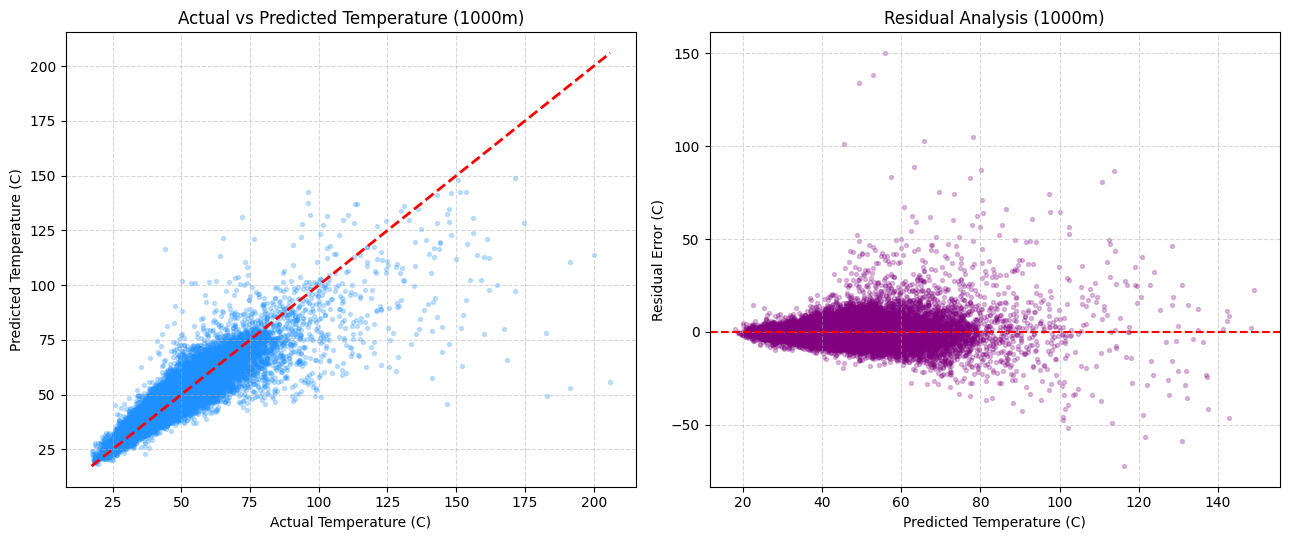

In [ ]:
# 1. Distribusi Suhu Target, Perbandingan RMSE Lintas Kedalaman, Aktual vs Prediksi, dan Plot Residual
plt.figure(figsize=(10, 5))
for col in target_cols:
    sns.kdeplot(df[col], fill=True, label=col)
plt.title('Target Temperature Distribution Across 5 Depth Strata', fontsize=13)
plt.xlabel('Temperature (C)')
plt.ylabel('Density')
plt.legend(title='Target Depth')
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'Visual_D_Data_Distribution.png'), dpi=300)
plt.show()

plt.figure(figsize=(9, 5))
for m_label, m_key, style, marker in [
    ('Random Forest (Optimized)', 'RF_Optuna_MultiOutput', '--', 'o'),
    ('XGBoost (Optimized)', 'XGB_Optuna_SingleOutput', '--', 's'),
    ('Simple Averaging Ensemble', 'Simple_Average_Ensemble', '-.', 'd'),
    ('Hybrid Stacking (Proposed)', 'Hybrid_Stacking_Proposed', '-', '^')
]:
    sub = df_ablation_full[df_ablation_full['Model'] == m_key]
    plt.plot(sub['Target_Depth'], sub['RMSE_C'], linestyle=style, marker=marker, linewidth=2.2, label=m_label)
plt.title('RMSE Comparison Across Subsurface Depths (1000m - 5000m)', fontsize=13)
plt.xlabel('Target Depth')
plt.ylabel('RMSE (C)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'Output_3_RMSE_vs_Depth.png'), dpi=300)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].scatter(Y[:, 0], oof_preds['Hybrid_Stacking_Proposed'][:, 0], alpha=0.25, s=8, color='dodgerblue')
axes[0].plot([Y[:, 0].min(), Y[:, 0].max()], [Y[:, 0].min(), Y[:, 0].max()], 'r--', lw=2)
axes[0].set_xlabel('Actual Temperature (C)')
axes[0].set_ylabel('Predicted Temperature (C)')
axes[0].set_title('Actual vs Predicted Temperature (1000m)', fontsize=12)
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].scatter(oof_preds['Hybrid_Stacking_Proposed'][:, 0], Y[:, 0] - oof_preds['Hybrid_Stacking_Proposed'][:, 0], alpha=0.25, s=8, color='purple')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted Temperature (C)')
axes[1].set_ylabel('Residual Error (C)')
axes[1].set_title('Residual Analysis (1000m)', fontsize=12)
axes[1].grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'Visual_A_B_Actual_Predicted_and_Residual.png'), dpi=300)
plt.show()

Statistik Numerik Diagram Taylor per Kedalaman:


,Target_Depth,Obs_SD_C,Pred_SD_C,Normalized_SD,Centered_RMSE_C,Normalized_CRMSE,Pearson_Correlation_r,R2_Score
0,T_1000m,9.0236,8.6023,0.9533,2.8368,0.3144,0.9493,0.9012
1,T_2000m,12.8565,12.4787,0.9706,3.1712,0.2467,0.9691,0.9392
2,T_3000m,16.4763,16.1007,0.9772,3.5774,0.2171,0.9761,0.9529
3,T_4000m,20.3799,20.0239,0.9825,3.9058,0.1917,0.9815,0.9633
4,T_5000m,25.0081,24.6531,0.9858,4.3364,0.1734,0.9849,0.9699


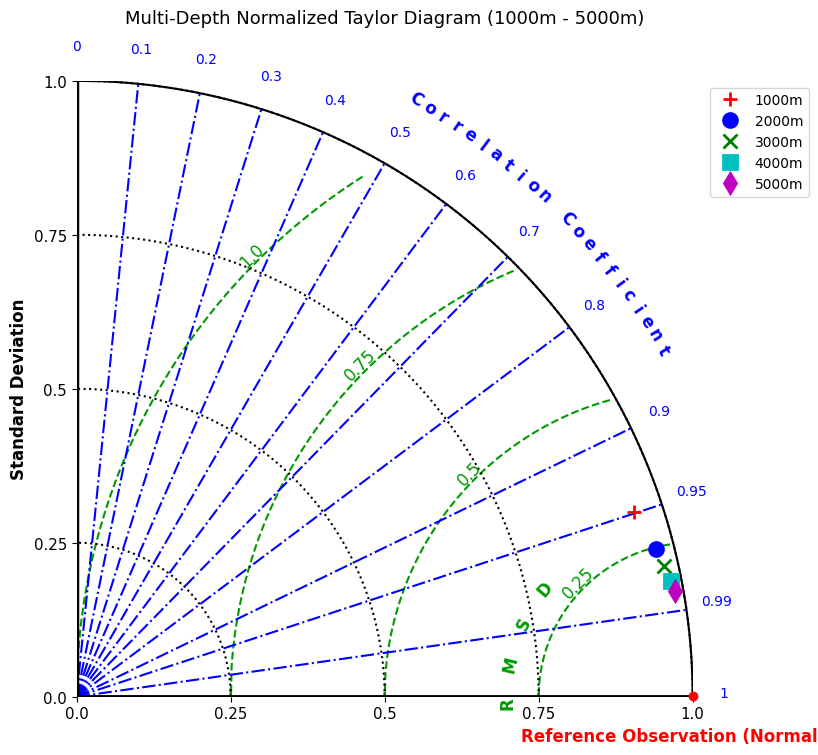

In [ ]:
# 2. Diagram Taylor Multi-Kedalaman
taylor_stats = []
for d, col in enumerate(target_cols):
    r_val = np.corrcoef(Y[:, d], oof_preds['Hybrid_Stacking_Proposed'][:, d])[0, 1]
    sd_obs = np.std(Y[:, d])
    sd_sim = np.std(oof_preds['Hybrid_Stacking_Proposed'][:, d])
    crmse_val = np.sqrt(np.mean(((oof_preds['Hybrid_Stacking_Proposed'][:, d] - np.mean(oof_preds['Hybrid_Stacking_Proposed'][:, d])) - (Y[:, d] - np.mean(Y[:, d])))**2))
    taylor_stats.append({
        'Target_Depth': col,
        'Obs_SD_C': sd_obs,
        'Pred_SD_C': sd_sim,
        'Normalized_SD': sd_sim / sd_obs,
        'Centered_RMSE_C': crmse_val,
        'Normalized_CRMSE': crmse_val / sd_obs,
        'Pearson_Correlation_r': r_val,
        'R2_Score': r2_score(Y[:, d], oof_preds['Hybrid_Stacking_Proposed'][:, d])
    })
df_taylor = pd.DataFrame(taylor_stats)
df_taylor.to_excel(os.path.join(OUT_DIR, 'Tabel_Statistik_Taylor_Diagram_Per_Kedalaman.xlsx'), index=False)
print('Statistik Numerik Diagram Taylor per Kedalaman:')
display(df_taylor.round(4))

sdev_norm = np.array([1.0] + df_taylor['Normalized_SD'].tolist())
crmse_norm = np.array([0.0] + df_taylor['Normalized_CRMSE'].tolist())
ccoe_norm = np.array([1.0] + df_taylor['Pearson_Correlation_r'].tolist())
labels_taylor = ['Observation', '1000m', '2000m', '3000m', '4000m', '5000m']

plt.figure(figsize=(8, 8))
sm.taylor_diagram(sdev_norm, crmse_norm, ccoe_norm, markerLabel=labels_taylor,
                  titleOBS='Reference Observation (Normalized)', markerlegend='on', colOBS='r', markerOBS='o')
plt.title('Multi-Depth Normalized Taylor Diagram (1000m - 5000m)', y=1.08, fontsize=13)
plt.savefig(os.path.join(OUT_DIR, 'Output_4_Taylor_Diagram_MultiDepth.png'), dpi=300, bbox_inches='tight')
plt.show()

Melatih model final dan mengekstrak SHAP Stacked Ensemble lintas 5 kedalaman...
Konsistensi Normalized Stacked SHAP Importance (%) Lintas 5 Kedalaman:


Target_Depth,Feature,T_1000m,T_2000m,T_3000m,T_4000m,T_5000m,Average_All_Depths_Pct,RF_Joint_Impurity_Pct
0,dVs_20km,29.93,24.93,18.90,14.16,12.11,20.01,12.05
1,crustal_thickness,17.89,17.83,18.51,19.72,21.12,19.01,12.54
2,Vp_7000m,6.71,15.34,16.17,20.50,18.02,15.35,37.01
3,dVs_60km,9.73,11.65,14.86,18.60,18.33,14.64,14.06
4,Vp_6000m,6.79,5.67,9.77,7.02,9.97,7.84,9.02
5,dVs_40km,7.85,7.01,6.05,5.48,4.64,6.21,3.05
6,gg_mantle_60km,5.46,4.97,5.10,5.39,7.38,5.66,4.71
7,elevation_detrend,5.26,4.63,4.45,4.38,4.15,4.58,2.88
8,dVpVs_60km,7.43,4.93,3.26,2.26,2.09,4.00,2.33
9,VpVs_60km,2.94,3.03,2.93,2.50,2.19,2.72,2.34


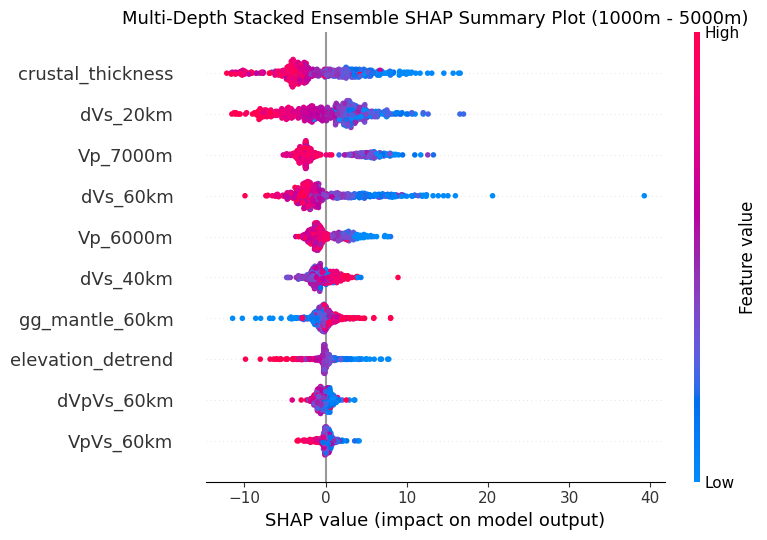

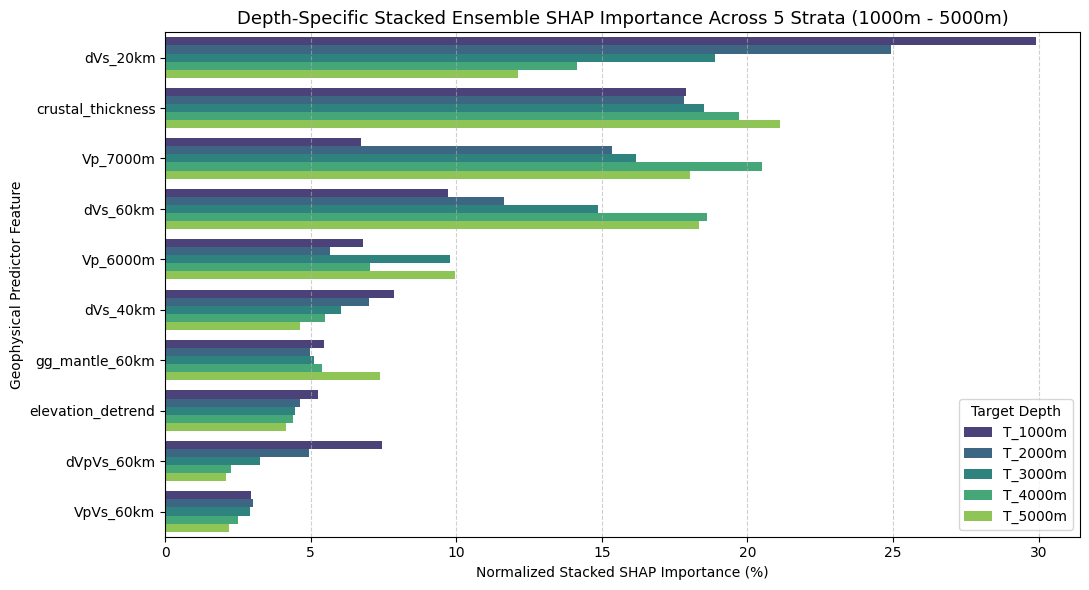

In [ ]:
# 3. Analisis SHAP Stacked Ensemble Lintas 5 Kedalaman (Menggunakan Bobot Meta-Learner Beta1*SHAP_RF + Beta2*SHAP_XGB)
print('Melatih model final dan mengekstrak SHAP Stacked Ensemble lintas 5 kedalaman...')
scaler_full = StandardScaler()
X_scaled_full = scaler_full.fit_transform(X_raw)

rng = np.random.default_rng(RANDOM_SEED)
shap_idx = rng.choice(len(X_scaled_full), size=500, replace=False)
X_shap_sample = X_scaled_full[shap_idx]

rf_full_joint = RandomForestRegressor(
    n_estimators=best_p['rf_n_estimators'], max_depth=best_p['rf_max_depth'], random_state=RANDOM_SEED, n_jobs=-1
).fit(X_scaled_full, Y)

exp_rf = shap.TreeExplainer(rf_full_joint)
sv_rf_all = exp_rf.shap_values(X_shap_sample)  # List 5 array atau array (N, 10, 5)

shap_depth_importance = []
shap_values_stacked_per_depth = {}

for d, col in enumerate(target_cols):
    xgb_d = XGBRegressor(
        n_estimators=best_p['xgb_n_estimators'],
        max_depth=best_p['xgb_max_depth'],
        learning_rate=best_p['xgb_learning_rate'],
        random_state=RANDOM_SEED,
        n_jobs=-1
    ).fit(X_scaled_full, Y[:, d])

    exp_xgb = shap.TreeExplainer(xgb_d)
    sv_xgb_d = exp_xgb.shap_values(X_shap_sample)
    sv_rf_d = sv_rf_all[d] if isinstance(sv_rf_all, list) else sv_rf_all[:, :, d]

    # Bobot Meta-Learner pada kedalaman d
    b1 = float(df_meta_summary.loc[df_meta_summary['Target_Depth'] == col, 'Weight_RF_Beta1'].values[0])
    b2 = float(df_meta_summary.loc[df_meta_summary['Target_Depth'] == col, 'Weight_XGB_Beta2'].values[0])

    # Kombinasi linier SHAP sesuai persamaan Meta-Learner Stacking
    sv_stack_d = b1 * sv_rf_d + b2 * sv_xgb_d
    shap_values_stacked_per_depth[col] = sv_stack_d

    mean_abs_sv = np.mean(np.abs(sv_stack_d), axis=0)
    norm_pct = (mean_abs_sv / np.sum(mean_abs_sv)) * 100.0

    for f_i, f_name in enumerate(fitur_terbaik):
        shap_depth_importance.append({
            'Target_Depth': col,
            'Feature': f_name,
            'Mean_Abs_Stacked_SHAP_C': mean_abs_sv[f_i],
            'Normalized_Stacked_SHAP_Pct': norm_pct[f_i],
            'RF_Gini_Importance_Pct': rf_full_joint.feature_importances_[f_i] * 100.0
        })

df_shap_depths = pd.DataFrame(shap_depth_importance)
df_shap_pivot = df_shap_depths.pivot(index='Feature', columns='Target_Depth', values='Normalized_Stacked_SHAP_Pct')
df_shap_pivot['Average_All_Depths_Pct'] = df_shap_pivot.mean(axis=1)
df_shap_pivot['RF_Joint_Impurity_Pct'] = [rf_full_joint.feature_importances_[fitur_terbaik.index(f)] * 100.0 for f in df_shap_pivot.index]
df_shap_pivot = df_shap_pivot.sort_values(by='Average_All_Depths_Pct', ascending=False).reset_index()

df_shap_pivot.to_excel(os.path.join(OUT_DIR, 'Tabel_7_SHAP_dan_Feature_Importance_Multi_Kedalaman.xlsx'), index=False)
print('Konsistensi Normalized Stacked SHAP Importance (%) Lintas 5 Kedalaman:')
display(df_shap_pivot.round(2))

sv_avg_all_depths = np.mean([shap_values_stacked_per_depth[c] for c in target_cols], axis=0)
plt.figure(figsize=(10, 6))
shap.summary_plot(sv_avg_all_depths, X_shap_sample, feature_names=fitur_terbaik, show=False)
plt.title('Multi-Depth Stacked Ensemble SHAP Summary Plot (1000m - 5000m)', fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'Output_2_SHAP_Plot_MultiDepth.png'), dpi=300, bbox_inches='tight')
plt.show()

plt.figure(figsize=(11, 6))
order_feats = df_shap_pivot['Feature'].tolist()
sns.barplot(data=df_shap_depths, x='Normalized_Stacked_SHAP_Pct', y='Feature', hue='Target_Depth', order=order_feats, palette='viridis')
plt.title('Depth-Specific Stacked Ensemble SHAP Importance Across 5 Strata (1000m - 5000m)', fontsize=13)
plt.xlabel('Normalized Stacked SHAP Importance (%)')
plt.ylabel('Geophysical Predictor Feature')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.legend(title='Target Depth', loc='lower right')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'Visual_C_Feature_Importance_MultiDepth.png'), dpi=300)
plt.show()

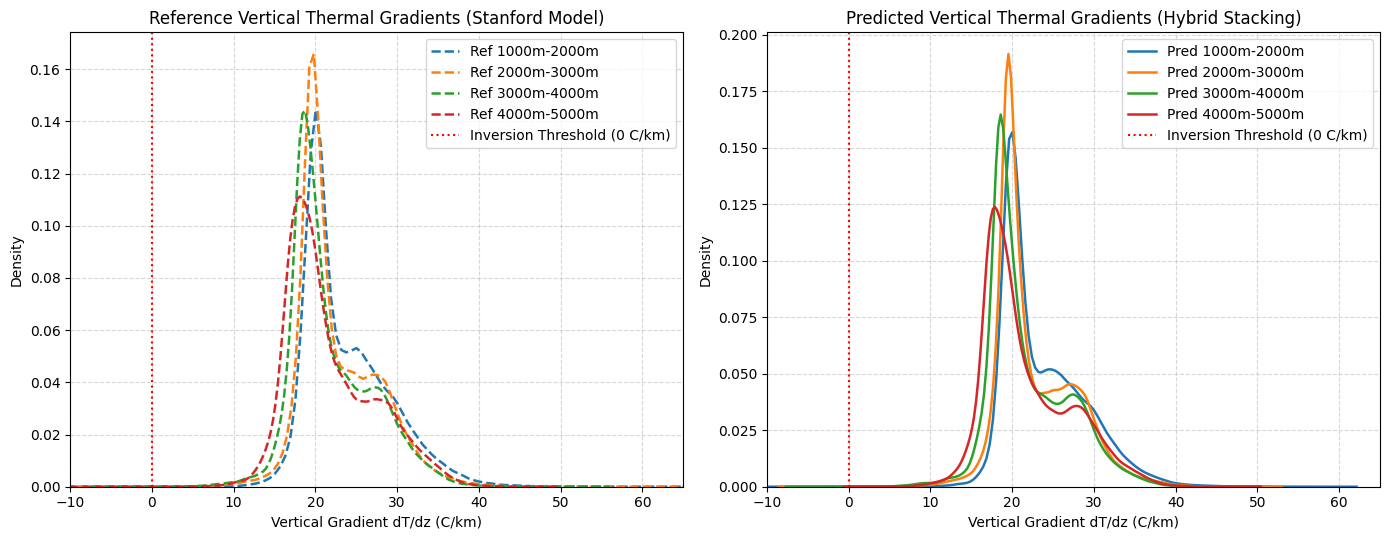

In [ ]:
# 4. Visualisasi Konsistensi Gradien Suhu Vertikal
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for idx, (int_label, i1, i2) in enumerate(intervals):
    g_ref = Y[:, i2] - Y[:, i1]
    g_pred = oof_preds['Hybrid_Stacking_Proposed'][:, i2] - oof_preds['Hybrid_Stacking_Proposed'][:, i1]
    sns.kdeplot(g_ref, ax=axes[0], linestyle='--', linewidth=1.8, label=f'Ref {int_label}')
    sns.kdeplot(g_pred, ax=axes[1], linewidth=1.8, label=f'Pred {int_label}')

axes[0].axvline(0, color='red', linestyle=':', label='Inversion Threshold (0 C/km)')
axes[0].set_title('Reference Vertical Thermal Gradients (Stanford Model)', fontsize=12)
axes[0].set_xlabel('Vertical Gradient dT/dz (C/km)')
axes[0].set_xlim(-10, 65)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].axvline(0, color='red', linestyle=':', label='Inversion Threshold (0 C/km)')
axes[1].set_title('Predicted Vertical Thermal Gradients (Hybrid Stacking)', fontsize=12)
axes[1].set_xlabel('Vertical Gradient dT/dz (C/km)')
axes[1].set_xlim(-10, 65)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'Visual_E_Vertical_Gradient_Consistency.png'), dpi=300)
plt.show()